# Customer Churn Analysis for Telecom Industry
**Elevate Labs Internship Project** | Sai Krishna

Predicting customer churn and deriving retention strategies using the IBM Telco Customer Churn dataset.

## 1. Load & Clean Data

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

sns.set_style('whitegrid')

df = pd.read_csv('data/Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'] * df['tenure'])
df['Churn_flag'] = (df['Churn'] == 'Yes').astype(int)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## 2. SQL Aggregation — Churn Drivers by Segment

In [2]:
conn = sqlite3.connect(':memory:')
df.to_sql('customers', conn, index=False, if_exists='replace')

contract_agg = pd.read_sql('''
    SELECT Contract, COUNT(*) AS total_customers, SUM(Churn_flag) AS churned,
           ROUND(100.0*SUM(Churn_flag)/COUNT(*),2) AS churn_rate_pct,
           ROUND(AVG(MonthlyCharges),2) AS avg_monthly_charges, ROUND(AVG(tenure),1) AS avg_tenure
    FROM customers GROUP BY Contract ORDER BY churn_rate_pct DESC;
''', conn)
contract_agg

,Contract,total_customers,churned,churn_rate_pct,avg_monthly_charges,avg_tenure
0,Month-to-month,3875,1655,42.71,66.40,18.0
1,One year,1473,166,11.27,65.05,42.0
2,Two year,1695,48,2.83,60.77,56.7


In [3]:
internet_agg = pd.read_sql('''
    SELECT InternetService, COUNT(*) AS total_customers,
           ROUND(100.0*SUM(Churn_flag)/COUNT(*),2) AS churn_rate_pct
    FROM customers GROUP BY InternetService ORDER BY churn_rate_pct DESC;
''', conn)
internet_agg

,InternetService,total_customers,churn_rate_pct
0,Fiber optic,3096,41.89
1,DSL,2421,18.96
2,No,1526,7.40


In [4]:
payment_agg = pd.read_sql('''
    SELECT PaymentMethod, COUNT(*) AS total_customers,
           ROUND(100.0*SUM(Churn_flag)/COUNT(*),2) AS churn_rate_pct
    FROM customers GROUP BY PaymentMethod ORDER BY churn_rate_pct DESC;
''', conn)
payment_agg

,PaymentMethod,total_customers,churn_rate_pct
0,Electronic check,2365,45.29
1,Mailed check,1612,19.11
2,Bank transfer (automatic),1544,16.71
3,Credit card (automatic),1522,15.24


Overall churn rate: 26.54%


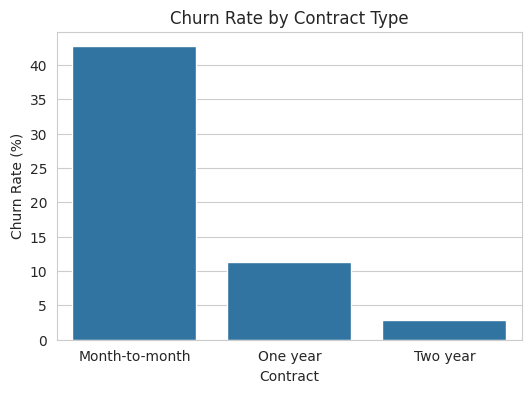

In [5]:
print(f"Overall churn rate: {df['Churn_flag'].mean()*100:.2f}%")
plt.figure(figsize=(6,4))
sns.barplot(data=contract_agg, x='Contract', y='churn_rate_pct')
plt.title('Churn Rate by Contract Type'); plt.ylabel('Churn Rate (%)'); plt.show()

## 3. Feature Engineering & Encoding

In [6]:
model_df = df.drop(columns=['customerID', 'Churn'])
cat_cols = model_df.select_dtypes(include='object').columns.tolist()
for c in cat_cols:
    model_df[c] = LabelEncoder().fit_transform(model_df[c])

X = model_df.drop(columns=['Churn_flag'])
y = model_df['Churn_flag']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train.shape, X_test.shape

/tmp/ipykernel_167/121720959.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = model_df.select_dtypes(include='object').columns.tolist()


((5634, 19), (1409, 19))

## 4. Binary Classification Model — Random Forest

In [7]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
proba = rf.predict_proba(X_test)[:,1]

print('Accuracy:', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall:', recall_score(y_test, pred))
print('F1:', f1_score(y_test, pred))
print('ROC-AUC:', roc_auc_score(y_test, proba))
print()
print(classification_report(y_test, pred))

Accuracy: 0.7679205110007097
Precision: 0.5444234404536862
Recall: 0.7700534759358288
F1: 0.6378737541528239
ROC-AUC: 0.8417435221783047

              precision    recall  f1-score   support

           0       0.90      0.77      0.83      1035
           1       0.54      0.77      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409



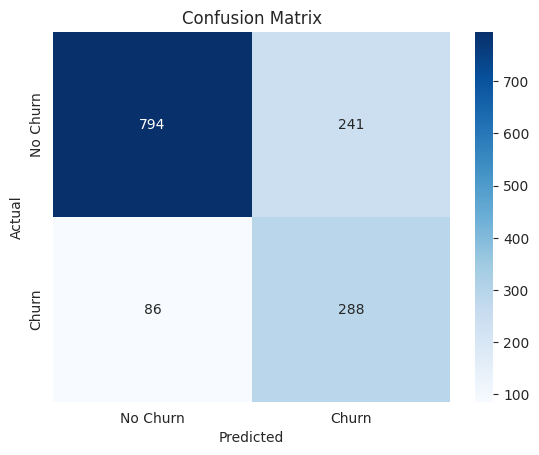

In [8]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn','Churn'], yticklabels=['No Churn','Churn'])
plt.title('Confusion Matrix'); plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.show()

## 5. Model Explainability — Top Churn Drivers (ELI5-style Feature Importance)

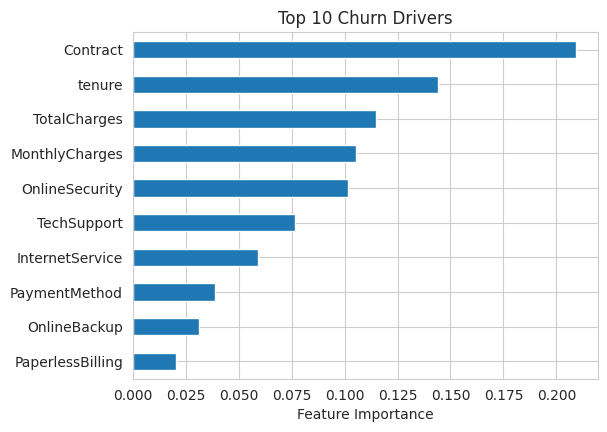

Contract            0.209045
tenure              0.143892
TotalCharges        0.115053
MonthlyCharges      0.105353
OnlineSecurity      0.101566
TechSupport         0.076635
InternetService     0.059155
PaymentMethod       0.038835
OnlineBackup        0.031141
PaperlessBilling    0.020411
dtype: float64

In [9]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10).sort_values().plot(kind='barh', figsize=(6,4.5))
plt.title('Top 10 Churn Drivers'); plt.xlabel('Feature Importance'); plt.show()
importances.head(10)

## 6. Customer Segmentation — At Risk / Loyal / Dormant

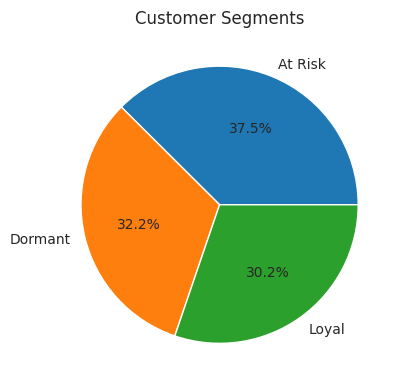

segment
At Risk    529
Dormant    454
Loyal      426
Name: count, dtype: int64

In [10]:
df_test = df.loc[X_test.index].copy()
df_test['churn_probability'] = proba

def segment(row):
    if row['churn_probability'] >= 0.5:
        return 'At Risk'
    elif row['tenure'] >= 24 and row['churn_probability'] < 0.2:
        return 'Loyal'
    else:
        return 'Dormant'

df_test['segment'] = df_test.apply(segment, axis=1)
seg_counts = df_test['segment'].value_counts()
seg_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(4.5,4.5))
plt.ylabel(''); plt.title('Customer Segments'); plt.show()
seg_counts

## 7. Recommendations

1. **Push month-to-month customers toward annual contracts** (discount or loyalty perk) — contract type is the single strongest churn driver (42.7% churn on month-to-month vs. 2.8% on two-year).
2. **Prioritize retention outreach to the "At Risk" segment** identified by the model (churn probability ≥ 0.5) — reach out before they leave, not after.
3. **Investigate fiber-optic service quality** — 41.9% churn vs. 18.96% for DSL suggests a pricing or reliability issue worth a deeper look.
4. **Nudge electronic-check payers toward automatic payment methods** — this group churns at nearly 3x the rate of automatic-payment customers, often a sign of low engagement.
5. **Bundle add-on services** (Online Security, Tech Support) — customers without these show up as high-importance churn features, suggesting they increase stickiness.